# Descriptives

## TOC 

- [Setup & Git](#setup)
- [Load and Preprocess Kern et al. & GPT Tweets](#load_preprocess_tweets)
- [Compare Prevalences](#compare_prevalences)
- [Check for Order Effects](#order_effects)

# Stuff to Check For / Analysis Ideas
- compare prevalences with those from Kern et al Paper 
- calculate agreement per tweets across the different conditions
- order effects (compare batch prompted with single-tweet prompted tweets)
- compare uncertainty measures per conditions (empirical entropy, confidence scores, etc.)

<a id="setup"></a>
## Setup & Git

In [1]:
import numpy as np
from matplotlib import pyplot as plt
import seaborn as sns
import os 
import pandas as pd
import re

<a id="load_preprocess_tweets"></a>
## Load and Preprocess the GPT Labelled Tweets

### Load the AS Paper tweets from Kern et al. (2023)

In [2]:
# load the full tweets as used by CK

# pd.set_option('max_colwidth', 1000)
pd.set_option('display.max_colwidth', 0)

# Load the tweet files
folder_path = 'Tweets_CK/'
train_file = 'full_train_s.csv'
test_file = 'full_test_s.csv'

train_df = pd.read_csv(os.path.join(folder_path, train_file))
test_df = pd.read_csv(os.path.join(folder_path, test_file))

# Reorder test_df columns to match train_df
test_df = test_df[train_df.columns]

# Add the 'original_split' column
train_df['original_split'] = 'train'
test_df['original_split'] = 'test'

# Combine them
tweets_full = pd.concat([train_df, test_df], ignore_index=True)

# Rename columns for a consistent style 
tweets_full = (tweets_full.
               rename(columns={'tweet.id': 'tweet_id', 
                               'batch.tweet': 'batch_tweet',
                               'hate.speech': 'hate_speech', 
                               'offensive.language': 'offensive_language'}))

# tweets_full.head(2)

In [3]:
# Reproduce Summary Table from Paper
summary = (tweets_full
 .groupby('version').agg(
    Annotations=('tweet_id', 'count'),
    Annotators=('id', 'nunique'),
    OL=('offensive_language', 'mean'),
    HS=('hate_speech', 'mean')  
).round(3))

# Add an 'overall' row as 'comparison ground truth'
total_annotations = summary['Annotations'].sum()
total_annotators = summary['Annotators'].sum()
weighted_OL = (summary['OL'] * summary['Annotations']).sum() / total_annotations
weighted_HS = (summary['HS'] * summary['Annotations']).sum() / total_annotations
overall = pd.DataFrame({
    'Annotations': [total_annotations],
    'Annotators': [total_annotators],
    'OL': [weighted_OL],
    'HS': [weighted_HS]
}, index=['overall'])

# Append the overall row to the original summary DataFrame
final_summary = pd.concat([summary, overall]).round(3)
final_summary

,Annotations,Annotators,OL,HS
A,9000,184,0.516,0.268
B,9000,183,0.588,0.296
C,8950,182,0.585,0.282
D,8950,179,0.544,0.335
E,9000,189,0.590,0.318
overall,44900,917,0.565,0.300


### Load and rbind the GPT Labeled Tweets

In [4]:
# load the ZERO-SHOT annotations 
DATE_TO_IMPORT = '2025_04_10'

files = os.listdir('Data_Collection/')
files_to_select = list(filter(lambda filename: filename.startswith(DATE_TO_IMPORT), files))
files_to_select = [f"Data_Collection/{filename}" for filename in files_to_select]

# read and concat files 
dataframes = [pd.read_csv(file) for file in files_to_select]
combined_df_z = pd.concat(dataframes, sort=False, ignore_index=True)
combined_df_z.sort_values(['batch_id', 'tweet_in_batch'], inplace=True)


# load the FEW-SHOT annotations 
DATE_TO_IMPORT = '2025_04_23'

files = os.listdir('Data_Collection/')
files_to_select = list(filter(lambda filename: filename.startswith(DATE_TO_IMPORT), files))
files_to_select = [f"Data_Collection/{filename}" for filename in files_to_select]

# read and concat files 
dataframes = [pd.read_csv(file) for file in files_to_select]
combined_df_f = pd.concat(dataframes, sort=False, ignore_index=True)
combined_df_f.sort_values(['batch_id', 'tweet_in_batch'], inplace=True)

# Concat the tweets and add zero- vs. few-shot column
combined_df_z.insert(5,'shot','zero-shot')
combined_df_f.insert(5,'shot','few-shot')
combined_df = pd.concat([combined_df_z, 
                         combined_df_f], sort=False, ignore_index=True)
# combined_df.head(3)

### Preprocess GPT Labels
- Get to long format 
- Quality Checks (Compliance)
- Create binary OL and HS indicator columns

In [5]:
# Get from Wide Format to Proper Long Format
### List of columns that are shared among all tweets
shared_cols = ['batch_id', 'tweet_in_batch', 'tweet_id', 'tweet', 
               'condition', 'shot']

### List to hold the DataFrame for each responder
df_list = []

# Loop over each responder identifier (R1, R2, R3)
for responder in ['R1', 'R2', 'R3']:
    # Create a new DataFrame from old columns and responder col
    df_temp = combined_df[shared_cols].copy()
    df_temp['responder'] = responder

    # Add the responder-specific columns by using the respective column names
    df_temp['label'] = combined_df[f'{responder}_label']
    df_temp['score'] = combined_df[f'{responder}_score']
    df_temp['Token1'] = combined_df[f'{responder}_Token1']
    df_temp['Token2'] = combined_df[f'{responder}_Token2']
    df_temp['Token3'] = combined_df[f'{responder}_Token3']

    # Append the new DataFrame to the list
    df_list.append(df_temp)

# Concatenate all responder DataFrames into one
df_long = pd.concat(df_list, ignore_index=True)

# create OL / HS Indicator Columns
df_long['OL'] = np.where(['OL' in label for label in df_long['label']], 1, 0)
df_long['HS'] = np.where(['HS' in label for label in df_long['label']], 1, 0)

# check NA counts for confidence scores per condition
# df_long.groupby('condition')['score'].apply(lambda x: x.isna().sum())
# df_long.head()

<a id="compare_prevalences"></a>
## Compute and Compare Overall Prevalences with those of the AS Paper

In [6]:
# Compare HS and OL count across conditions 
tasks = ['A','B','C.OL', 'C.HS']
modes = ['', '_conf', '_batch', '_batch_conf']
custom_order = [t + m for m in modes for t in tasks]
shot_order = ['zero-shot', 'few-shot']


# multi-level index to get order we want
cond_shot_idx = pd.MultiIndex.from_product(
    [custom_order, shot_order],
    names=['condition', 'shot']
)

(df_long
 .groupby(['condition', 'shot'])
 .mean(numeric_only=True)[['OL', 'HS', 'score']]
 .round(2)
 .reindex(cond_shot_idx)         
 .head(16)
)


OL    HS  score
condition shot                        
A         zero-shot  0.76  0.47 NaN   
          few-shot   0.56  0.40 NaN   
B         zero-shot  0.65  0.43 NaN   
          few-shot   0.52  0.36 NaN   
C.OL      zero-shot  0.76  0.00 NaN   
          few-shot   0.68  0.00 NaN   
C.HS      zero-shot  0.00  0.55 NaN   
          few-shot   0.00  0.38 NaN   
A_conf    zero-shot  0.80  0.44  3.43 
          few-shot   0.59  0.42  3.55 
B_conf    zero-shot  0.76  0.48  3.44 
          few-shot   0.62  0.38  3.58 
C.OL_conf zero-shot  0.78  0.00  3.56 
          few-shot   0.74  0.00  3.58 
C.HS_conf zero-shot  0.00  0.56  3.41 
          few-shot   0.00  0.39  3.28

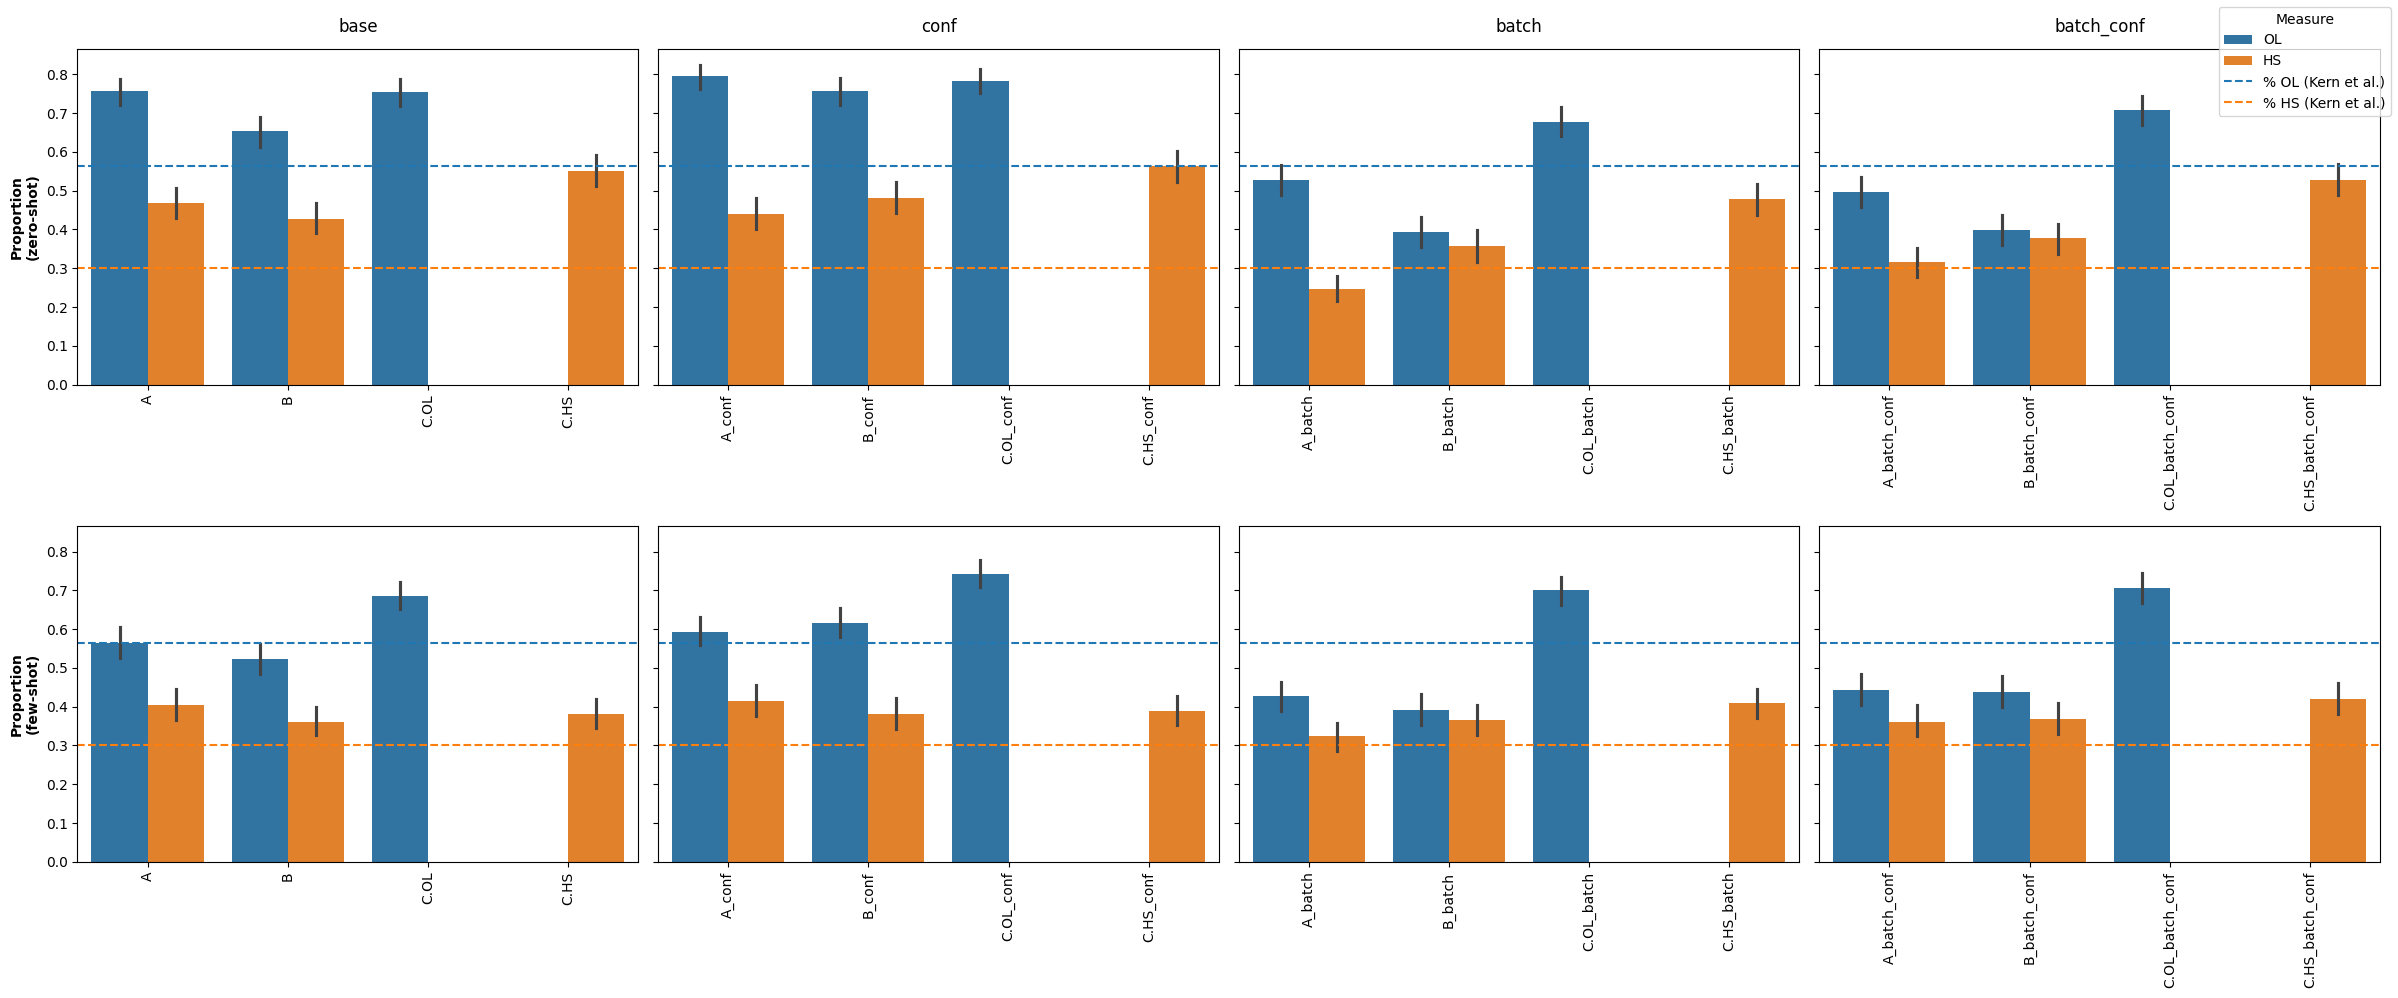

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

# ------------------------------------------------------------------
# 0 )  make sure df_long already has a column called  'shot'
#      whose values are exactly 'zero-shot' or 'few-shot'
# ------------------------------------------------------------------

# use the overall HS/OL from Kern et al. (2023) as comparison
overall_OL = final_summary.loc['overall']['OL']
overall_HS = final_summary.loc['overall']['HS']


shot_order   = ['zero-shot', 'few-shot']
group_order  = ['base', 'conf', 'batch', 'batch_conf']

# ------------------------------------------------------------------
# 1 )  build the long-format dataframe
# ------------------------------------------------------------------
df          = df_long.copy()
df['base_condition'] = df['condition'].str.split('_').str[0]

def extract_group_type(x):
    if '_' not in x:                return 'base'
    elif x.endswith('_batch_conf'): return 'batch_conf'
    elif x.endswith('_conf'):       return 'conf'
    elif x.endswith('_batch'):      return 'batch'
    else:                           return 'other'

df['group_type'] = df['condition'].apply(extract_group_type)

df_melt = (
    df
    .melt(id_vars=['condition','base_condition','group_type','shot'],
          value_vars=['OL','HS'],
          var_name='Measure',
          value_name='Value')
)

# ------------------------------------------------------------------
# 2 )  build  2 rows × 4 cols  of sub-plots
# ------------------------------------------------------------------
fig, axes = plt.subplots(
    nrows=2, ncols=len(group_order), figsize=(24, 10), sharey=True
)

for col, grp in enumerate(group_order):          # iterate over the 4 columns
    # the condition order is identical for both rows
    if   grp == 'base':
        cond_order = [c for c in custom_order if '_' not in c]
    elif grp == 'conf':
        cond_order = [c for c in custom_order if c.endswith('_conf') and
                                              not c.endswith('_batch_conf')]
    elif grp == 'batch':
        cond_order = [c for c in custom_order if c.endswith('_batch') and
                                              not c.endswith('_batch_conf')]
    elif grp == 'batch_conf':
        cond_order = [c for c in custom_order if c.endswith('_batch_conf')]

    for row, shot in enumerate(shot_order):      # 0 = zero-shot, 1 = few-shot
        ax      = axes[row, col]
        df_plot = df_melt[(df_melt['group_type'] == grp) &
                          (df_melt['shot']       == shot)]

        sns.barplot(
            data=df_plot,
            x='condition', y='Value', hue='Measure',
            order=cond_order, dodge=True, ax=ax,
            palette={'OL': '#1f77b4', 'HS': '#ff7f0e'}
        )

        # horizontal reference lines
        ax.axhline(overall_OL, ls='--', color='#1f77b4', label="% OL (Kern et al.)")
        ax.axhline(overall_HS, ls='--', color='#ff7f0e', label="% HS (Kern et al.)")
        

        # cosmetics
        if row == 0:                       # title only once (top row)
            ax.set_title(grp, pad=12)
        if col == 0:                       # y-label only on the leftmost col
            ax.set_ylabel('Proportion')
        else:
            ax.set_ylabel('')
        ax.set_xlabel('')
        ax.tick_params(axis='x', rotation=90)
        ax.legend().remove()

# ------------------------------------------------------------------
# 3 )  add row labels and a single figure-level legend
# ------------------------------------------------------------------
axes[0,0].set_ylabel('Proportion\n(zero-shot)', weight='bold')
axes[1,0].set_ylabel('Proportion\n(few-shot)',  weight='bold')

handles, labels = axes[0,0].get_legend_handles_labels()
fig.legend(handles, labels, title='Measure', loc='upper right')

plt.tight_layout()
plt.show()
fig.savefig("Plots/hs_ol_descr.png",   dpi=300, bbox_inches="tight") 


Notes to the above, it seems as:  
- labelling proportions are by far higher than in the Kern et al Paper
- asking for a confidence score in general increases the OS/HS labelling probability
- using batch prompting in general decreases the labelling probability (rather strong) 
- few-shot seems to overall achieve better calibration (i.e., closer to the 'gold standard' labels in Kern et al

## Rater Agreement of GPT and Kern Labelers

TODO: Check which agreement values to calculate
Currently: Fleiss' Kappa on Diagonal (as there are 3 raters)  
and Cohen's Kappa on the Off Diagonal (as there are always 2 modal ratings per tweet)

In [8]:
# for each tweet and each condition, calculate: 
# 1) Mode for HS and OL
# 2) Mean for HS and OL 
# 3) SD for HS/OL ratings 

from utils.general import mode_value

tweet_level_df = (df_long
                  .groupby(['tweet_id', 'condition', 'shot',
                             'batch_id', 'tweet_in_batch'])
                  .agg(
                        label_count = ('tweet_id', 'count'),
                        HS_mode = ('HS', mode_value),
                        HS_mean = ('HS', 'mean'),
                        HS_std = ('HS', 'std'),
                        OL_mode = ('OL', mode_value),
                        OL_mean = ('OL', 'mean'),
                        OL_std = ('OL', 'std')
).reset_index())

df_long.head(2) # one row per respondent 
print(f'Rows df_long: {df_long.shape[0]}')
print(f'Rows tweet_level_df: {tweet_level_df.shape[0]}')
tweet_level_df.head(2) # one row per tweet x condition

Rows df_long: 19200
Rows tweet_level_df: 6400


,tweet_id,condition,shot,batch_id,tweet_in_batch,label_count,HS_mode,HS_mean,HS_std,OL_mode,OL_mean,OL_std
0,7,A,few-shot,132,3,3,0,0.0,0.0,1,1.0,0.0
1,7,A,zero-shot,132,3,3,0,0.0,0.0,1,1.0,0.0


### Calculate Rater Agreements 
#### a) within conditions (i.e., agreement of the 3 ratings within condition) --> Fleiss' Kappa
#### b) between conditions (i.e., agreement of modal ratings between 2 conditions) --> Cohen's Kappa

In [9]:
from utils.agreements import within_agreement_fleiss_kappa, between_agreement_cohens_kappa
import warnings

# Aggregate Modal Ratings per Tweet per Condition (ZERO-SHOT)
df_agg = (df_long
          .groupby(['tweet_id', 'condition', 'shot']).agg(
              modal_HS = ('HS', mode_value),
              modal_OL = ('OL', mode_value)
              ).reset_index())


## Get the Across-Condition Agreement Matrices
# Get the list of conditions.
conditions = sorted(df_long['condition'].unique())

# Prepare two empty DataFrames for the agreement matrices (one for HS and one for OL).
across_HS_zero = pd.DataFrame(index=[c for c in conditions if "C.OL" not in c], 
                         columns=[c for c in conditions if "C.OL" not in c], 
                         dtype=float)
across_OL_zero = pd.DataFrame(index=[c for c in conditions if "C.HS" not in c], 
                         columns=[c for c in conditions if "C.HS" not in c], 
                         dtype=float)
across_HS_few = across_HS_zero.copy()
across_OL_few = across_OL_zero.copy()

# For each pair of conditions, fill the matrix
HS_conditions= [c for c in conditions if "C.OL" not in c]
OL_conditions= [c for c in conditions if "C.HS" not in c]


for cond_i in conditions:
    for cond_j in conditions:
        if cond_i == cond_j:
            # --> same condition: within agreement (fleiss' kappa)
            with warnings.catch_warnings():
                warnings.simplefilter("ignore") # ignore warnings for kappa
                # if all raters gave the same response
                # Diagonals: Compute Fleiss' kappa on the raw ratings from df_long.
                across_HS_zero.loc[cond_i, cond_j] = (within_agreement_fleiss_kappa(
                    df_long[df_long['shot'] == 'zero-shot'], 
                    cond_i, rating_column='HS'))
                across_HS_few.loc[cond_i, cond_j] = (within_agreement_fleiss_kappa(
                    df_long[df_long['shot'] == 'few-shot'], 
                    cond_i, rating_column='HS'))
                across_OL_zero.loc[cond_i, cond_j] = (within_agreement_fleiss_kappa(
                    df_long[df_long['shot'] == 'zero-shot'], 
                    cond_i, rating_column='OL'))
                across_OL_few.loc[cond_i, cond_j] = (within_agreement_fleiss_kappa(
                    df_long[df_long['shot'] == 'few-shot'], 
                    cond_i, rating_column='OL'))
        else:
            # --> different condition: between agreement of modes (cohen's kappa)
            with warnings.catch_warnings():
                # warnings.simplefilter("ignore")
                # Off-diagonals: Compute Cohen's kappa on the modal ratings from df_agg.
                across_HS_zero.loc[cond_i, cond_j] = between_agreement_cohens_kappa(
                    df_agg[(df_agg['condition'].isin(HS_conditions)) &
                           (df_agg['shot'] == 'zero-shot')], 
                    cond_i, cond_j, 'HS')
                across_HS_few.loc[cond_i, cond_j] = between_agreement_cohens_kappa(
                    df_agg[(df_agg['condition'].isin(HS_conditions)) &
                           (df_agg['shot'] == 'few-shot')],
                    cond_i, cond_j, 'HS')
                across_OL_zero.loc[cond_i, cond_j] = between_agreement_cohens_kappa(
                    df_agg[(df_agg['condition'].isin(OL_conditions)) &
                           (df_agg['shot'] == 'zero-shot')], 
                    cond_i, cond_j, 'OL')
                across_OL_few.loc[cond_i, cond_j] = between_agreement_cohens_kappa(
                    df_agg[(df_agg['condition'].isin(OL_conditions)) &
                           (df_agg['shot'] == 'few-shot')],
                    cond_i, cond_j, 'OL')
                

In [10]:
from statsmodels.stats.inter_rater import to_table, cohens_kappa

# from sklearn.metrics import cohen_kappa_score
# from utils.general import mode_value, to_table, cohens_kappa

# 1) Compute the global (15-rater) mode for both outcomes
global_HS = tweets_full.groupby('tweet_id')['hate_speech'].agg(mode_value)
global_OL = tweets_full.groupby('tweet_id')['offensive_language'].agg(mode_value)

# 2) Map them into your aggregated df
df_agg['global_HS'] = df_agg['tweet_id'].map(global_HS)
df_agg['global_OL'] = df_agg['tweet_id'].map(global_OL)

# 3) Prepare lists of outcomes, shot-types, and conditions
outcomes = ['HS', 'OL']
shots    = df_agg['shot'].unique()         # e.g. ['few-shot','zero-shot']
conds    = df_agg['condition'].unique()    # your various model/condition labels

# 4) Loop over outcome × shot and build one kappa-vs-condition Series each,
#    then wrap it into a DataFrame with a “kappa” column.
kappa_dfs = { outcome: {} for outcome in outcomes }

for outcome in outcomes:
    # the two columns we’ll compare are “modal_{outcome}” vs “global_{outcome}”
    global_col = f'global_{outcome}'
    modal_col  = f'modal_{outcome}'
    
    for shot in shots:
        d = {}
        for cond in conds:
            sel = df_agg[
                (df_agg['shot'] == shot) & 
                (df_agg['condition'] == cond)
            ]
            valid = sel[global_col].notna() & sel[modal_col].notna()
            if valid.sum() > 0:
                with warnings.catch_warnings():
                    warnings.simplefilter("ignore")
                    # format for your cohens_kappa helper
                    tbl = to_table(sel.loc[valid, [modal_col, global_col]].copy())[0]
                    k = cohens_kappa(tbl)['kappa']
            else:
                k = np.nan
            d[cond] = k
        # one DataFrame per (outcome,-shot)
        kappa_dfs[outcome][shot] = pd.DataFrame.from_dict(
            d, orient='index', columns=['kappa']
        )

# format:
# print(kappa_dfs['OL']['few-shot'])

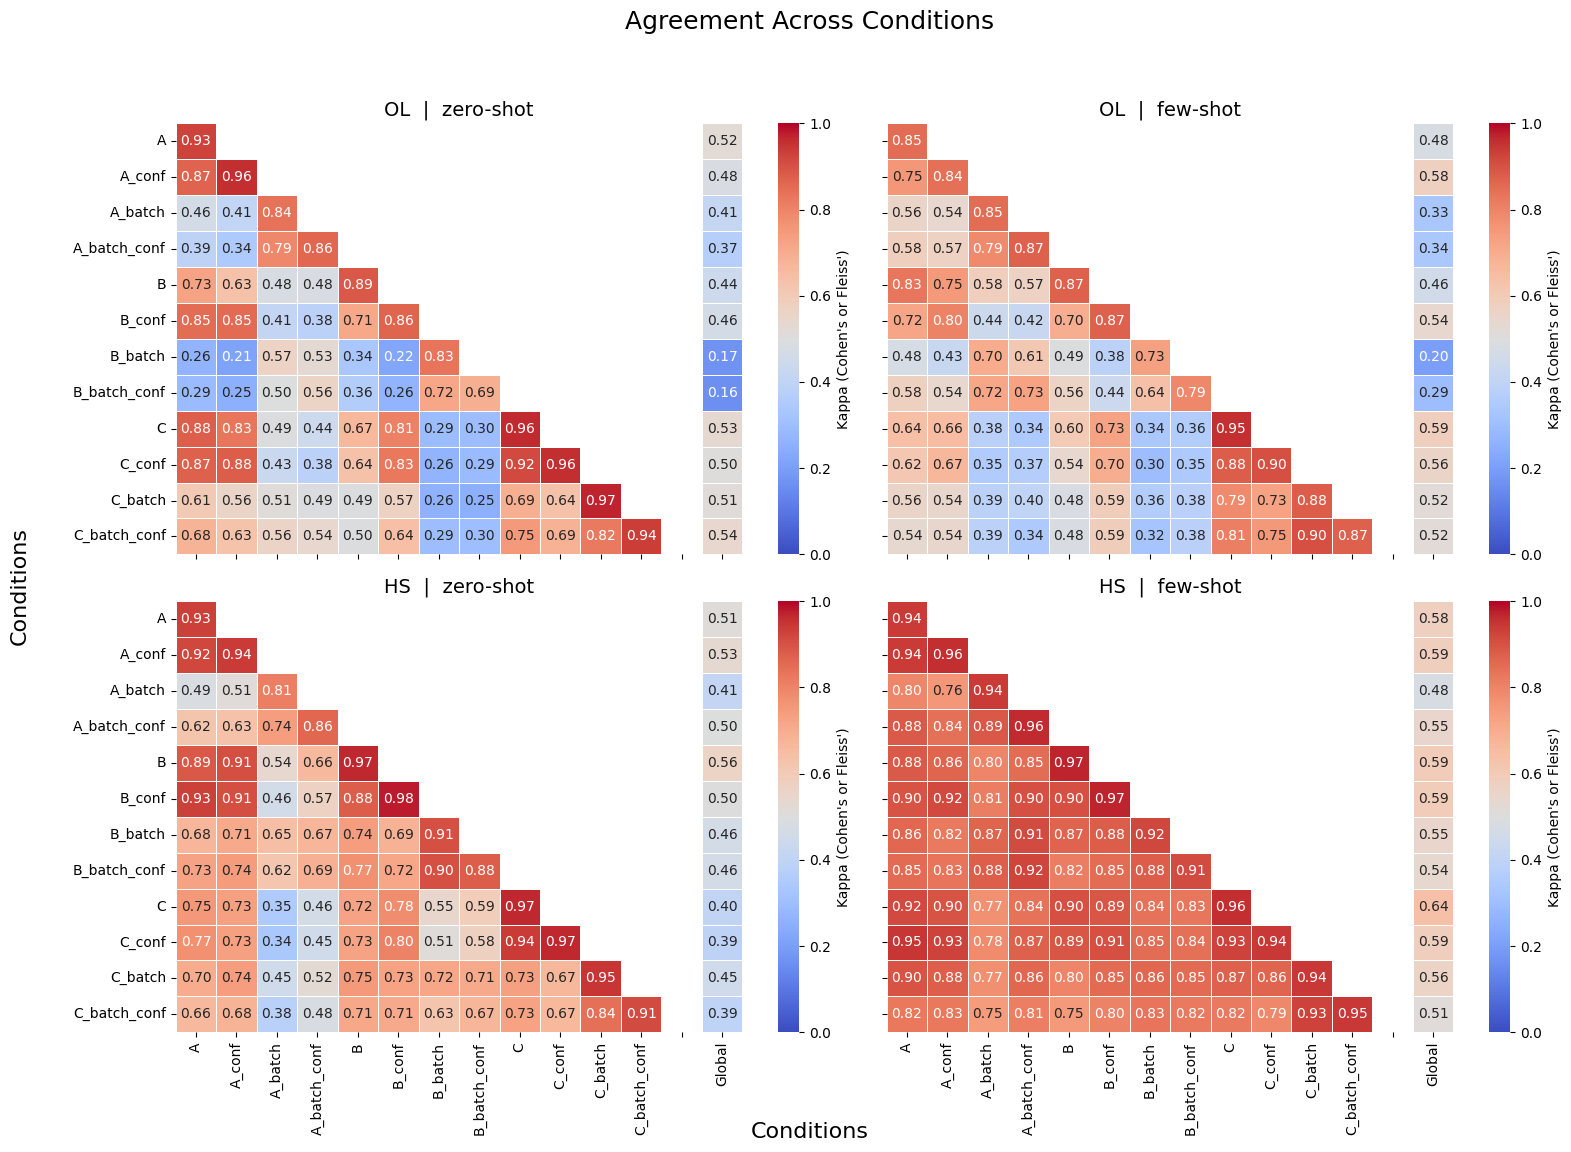

In [12]:
# PLOT 
# 1) define your dimension ordering
outcomes = ['OL', 'HS']    # → row 0 = OL, row 1 = HS
shots    = ['zero', 'few'] # → col 0 = zero-shot, col 1 = few-shot

# 2) build one "coolwarm" colormap and force NaNs to white
cmap = sns.color_palette("coolwarm", as_cmap=True)
cmap.set_bad(color='white')

# 3 rename the C conditions s.t. they no longer include the .OL and .HS 

# 3) make a 2×2 grid, sharing axes so panels align
fig, axes = plt.subplots(2, 2, figsize=(16, 12), sharex=True, sharey=True)

for outcome in outcomes:
    for shot in shots:
        # pick the right axis
        row = outcomes.index(outcome)
        col = shots.index(shot)
        ax  = axes[row, col]

        # --- reproduce your data-prep steps ---
        x_shot       = f'{shot}-shot'
        other        = [o for o in outcomes if o != outcome][0]
        no_cond      = f'C.{other}'
        kappa_df     = kappa_dfs[outcome][x_shot]
        global_kappa = kappa_df.squeeze()
        target_df    = eval(f'across_{outcome}_{shot}')

        cm = target_df.copy()
        cm['Global'] = global_kappa

        # insert a blank "gap" column
        gap       = ""
        orig_cols = list(target_df.columns)
        cm[gap]   = np.nan
        cm        = cm[orig_cols + [gap, 'Global']]

        # drop the mismatch‐pair rows & cols
        cm = cm.loc[:, ~cm.columns.str.contains(no_cond)]
        cm = cm[~cm.index.str.contains(no_cond)]
        
        # remove the .OL and .HS substrings from colnames/rownames using regex
        pattern = r'\.(?:OL|HS)'  # matches “.OL” or “.HS"
        cm.columns = cm.columns.str.replace(pattern, '', regex=True)
        cm.index   = cm.index.str.replace(pattern, '', regex=True)

        # define two‐level ordering
        prefixes = ['A', 'B', 'C']
        suffixes = ['', '_conf', '_batch', '_batch_conf']
        cond_order = [p + s for p in prefixes for s in suffixes]

        # keep only those that actually exist in cm (filters out any missing)
        cond_order = [c for c in cond_order if c in cm.index]

        # now reindex: first those conditions, then the gap column, then Global
        cols_order = cond_order + [gap, 'Global']
        cm = cm.reindex(index=cond_order, columns=cols_order)
        
        
        # build the upper‐triangle mask for the condition block
        n          = len([c for c in cm.columns if c not in [gap, 'Global']])
        mask_sub   = np.triu(np.ones((n, n), dtype=bool), k=1)
        mask_extra = np.zeros((n, 2), dtype=bool)
        mask       = np.hstack([mask_sub, mask_extra])

        # --- draw with the shared coolwarm cmap & fixed scale 0→1 ---
        sns.heatmap(
            cm,
            mask=mask,
            annot=True,
            fmt=".2f",
            cmap=cmap,
            vmin=0,
            vmax=1,
            cbar_kws={'label': "Kappa (Cohen's or Fleiss')"},
            linewidths=0.5,
            linecolor='white',
            ax=ax, 
            yticklabels=True
        )
        
        
        # tidy up each subplot
        ax.set_title(f"{outcome}  |  {shot}-shot", fontsize=14)
        ax.xaxis.tick_bottom()
        ax.set_xlabel("")
        ax.set_ylabel("")

# 4) add global labels & title
fig.text(0.5, 0.04, "Conditions", ha='center', fontsize=16)
fig.text(0.00, 0.5, "Conditions", va='center', rotation='vertical', fontsize=16)
fig.suptitle("Agreement Across Conditions", fontsize=18, y=0.98)

plt.tight_layout(rect=[0.03, 0.03, 1, 0.95])
plt.show()

# Save Figure 
fig.savefig("Plots/agreements.png",   dpi=300, bbox_inches="tight") 


What can we see here?
- Batch Prompts seem to have stronger within variability and also lower agreement with ground truth
- overall agreement with ground truth is rather low 
- non batch stuff shows better agreement scores 

In [13]:
# test for one specific cell --> Across (Cohen's Kappa)
outcome = 'HS'
shot = 'zero'
print(f'Outcome of Interest: {outcome}')
print(f'Shot Condition of Interest: {shot}-shot')


### COHENs KAPPA
conditions_to_compare = ['A', 'A_conf']

dat = df_agg[(df_agg['shot'] == f'{shot}-shot') & 
       (df_agg['condition'].isin(conditions_to_compare))]
dat = dat[['condition','tweet_id', f'modal_{outcome}']]
x = dat[dat['condition'] == conditions_to_compare[0]][['tweet_id', f'modal_{outcome}']]
y = dat[dat['condition'] == conditions_to_compare[1]][['tweet_id', f'modal_{outcome}']]


# Merge on tweet_id 
# df with 2 cols: modal rating cond1, modal rating cond2 (tweet_id dropped)
merged = pd.merge(x, y, on='tweet_id').drop('tweet_id', axis = 1)
# format for statsmodels.kappa
merged_formated = to_table(merged.copy())[0] 
# Compute Cohen's kappa between the two sets of modal ratings.
kappa_results = cohens_kappa(merged_formated)
kappa = kappa_results['kappa']
print(f"""Example Cohen's Kappa (across) for the conditions {conditions_to_compare[0]} & {conditions_to_compare[1]}: {round(kappa,2)}""")


# FLEISS KAPPA
# test for one specific diagonal cell --> Within (Fleiss Kappa)
condition_for_fleiss = 'A'
sub = df_long[(df_long['condition'] == condition_for_fleiss) & 
        (df_long['shot'] == f'{shot}-shot')][['tweet_id', 'responder', outcome]]


categories = sorted(sub[outcome].dropna().unique())
# Pivot the data so rows are tweet_ids and columns are rating categories
pivot = sub.pivot_table(index='tweet_id', 
                        columns=outcome, 
                        aggfunc='size', 
                        fill_value=0)
# Ensure that every expected category appears in the pivot table
for cat in categories:
    if cat not in pivot.columns:
        pivot[cat] = 0
pivot = pivot[categories]  # re-order columns in ascending order
M = pivot.to_numpy()
# Use the prepackaged fleiss_kappa from statsmodels
from statsmodels.stats.inter_rater import fleiss_kappa
fleiss_kappa_val = fleiss_kappa(M)
print(f"""Example Fleiss' Kappa (within) for the condition {condition_for_fleiss}: {round(fleiss_kappa_val,2)}""")

Outcome of Interest: HS
Shot Condition of Interest: zero-shot
Example Cohen's Kappa (across) for the conditions A & A_conf: 0.92
Example Fleiss' Kappa (within) for the condition A: 0.93
